# Week 7a: Comparing advection methods

FTCS, Lax, Lax-Wendroff and upwind on the same wave pulse, with periodic boundaries. The exact solution is the initial pulse shifted by ct, so every difference is numerical error.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

names = {1: 'FTCS', 2: 'Lax', 3: 'Lax-Wendroff', 4: 'Upwind'}

# Parameters shared by all runs below
N = 100           # Number of grid points
L = 1.            # The system extends from x=-L/2 to x=L/2
c = 1.            # Wave speed
sigma = 0.1       # Width of the Gaussian pulse
h = L/N           # Grid size (periodic)
print(f"h = {h},  h/c = {h/c}  (largest stable time step)")

h = 0.01,  h/c = 0.01  (largest stable time step)


## Comparing the four methods

The main loop of advect (Lecture 7b), wrapped in a function so every method runs with the same N and τ (cτ/h = 0.8). Lax, Lax-Wendroff and upwind go once around the system; FTCS is stopped after 40 steps because it blows up.

FTCS          peak after 40 steps: 4.42
Lax           peak after 125 steps: 0.181
Lax-Wendroff  peak after 125 steps: 0.939
Upwind        peak after 125 steps: 0.4


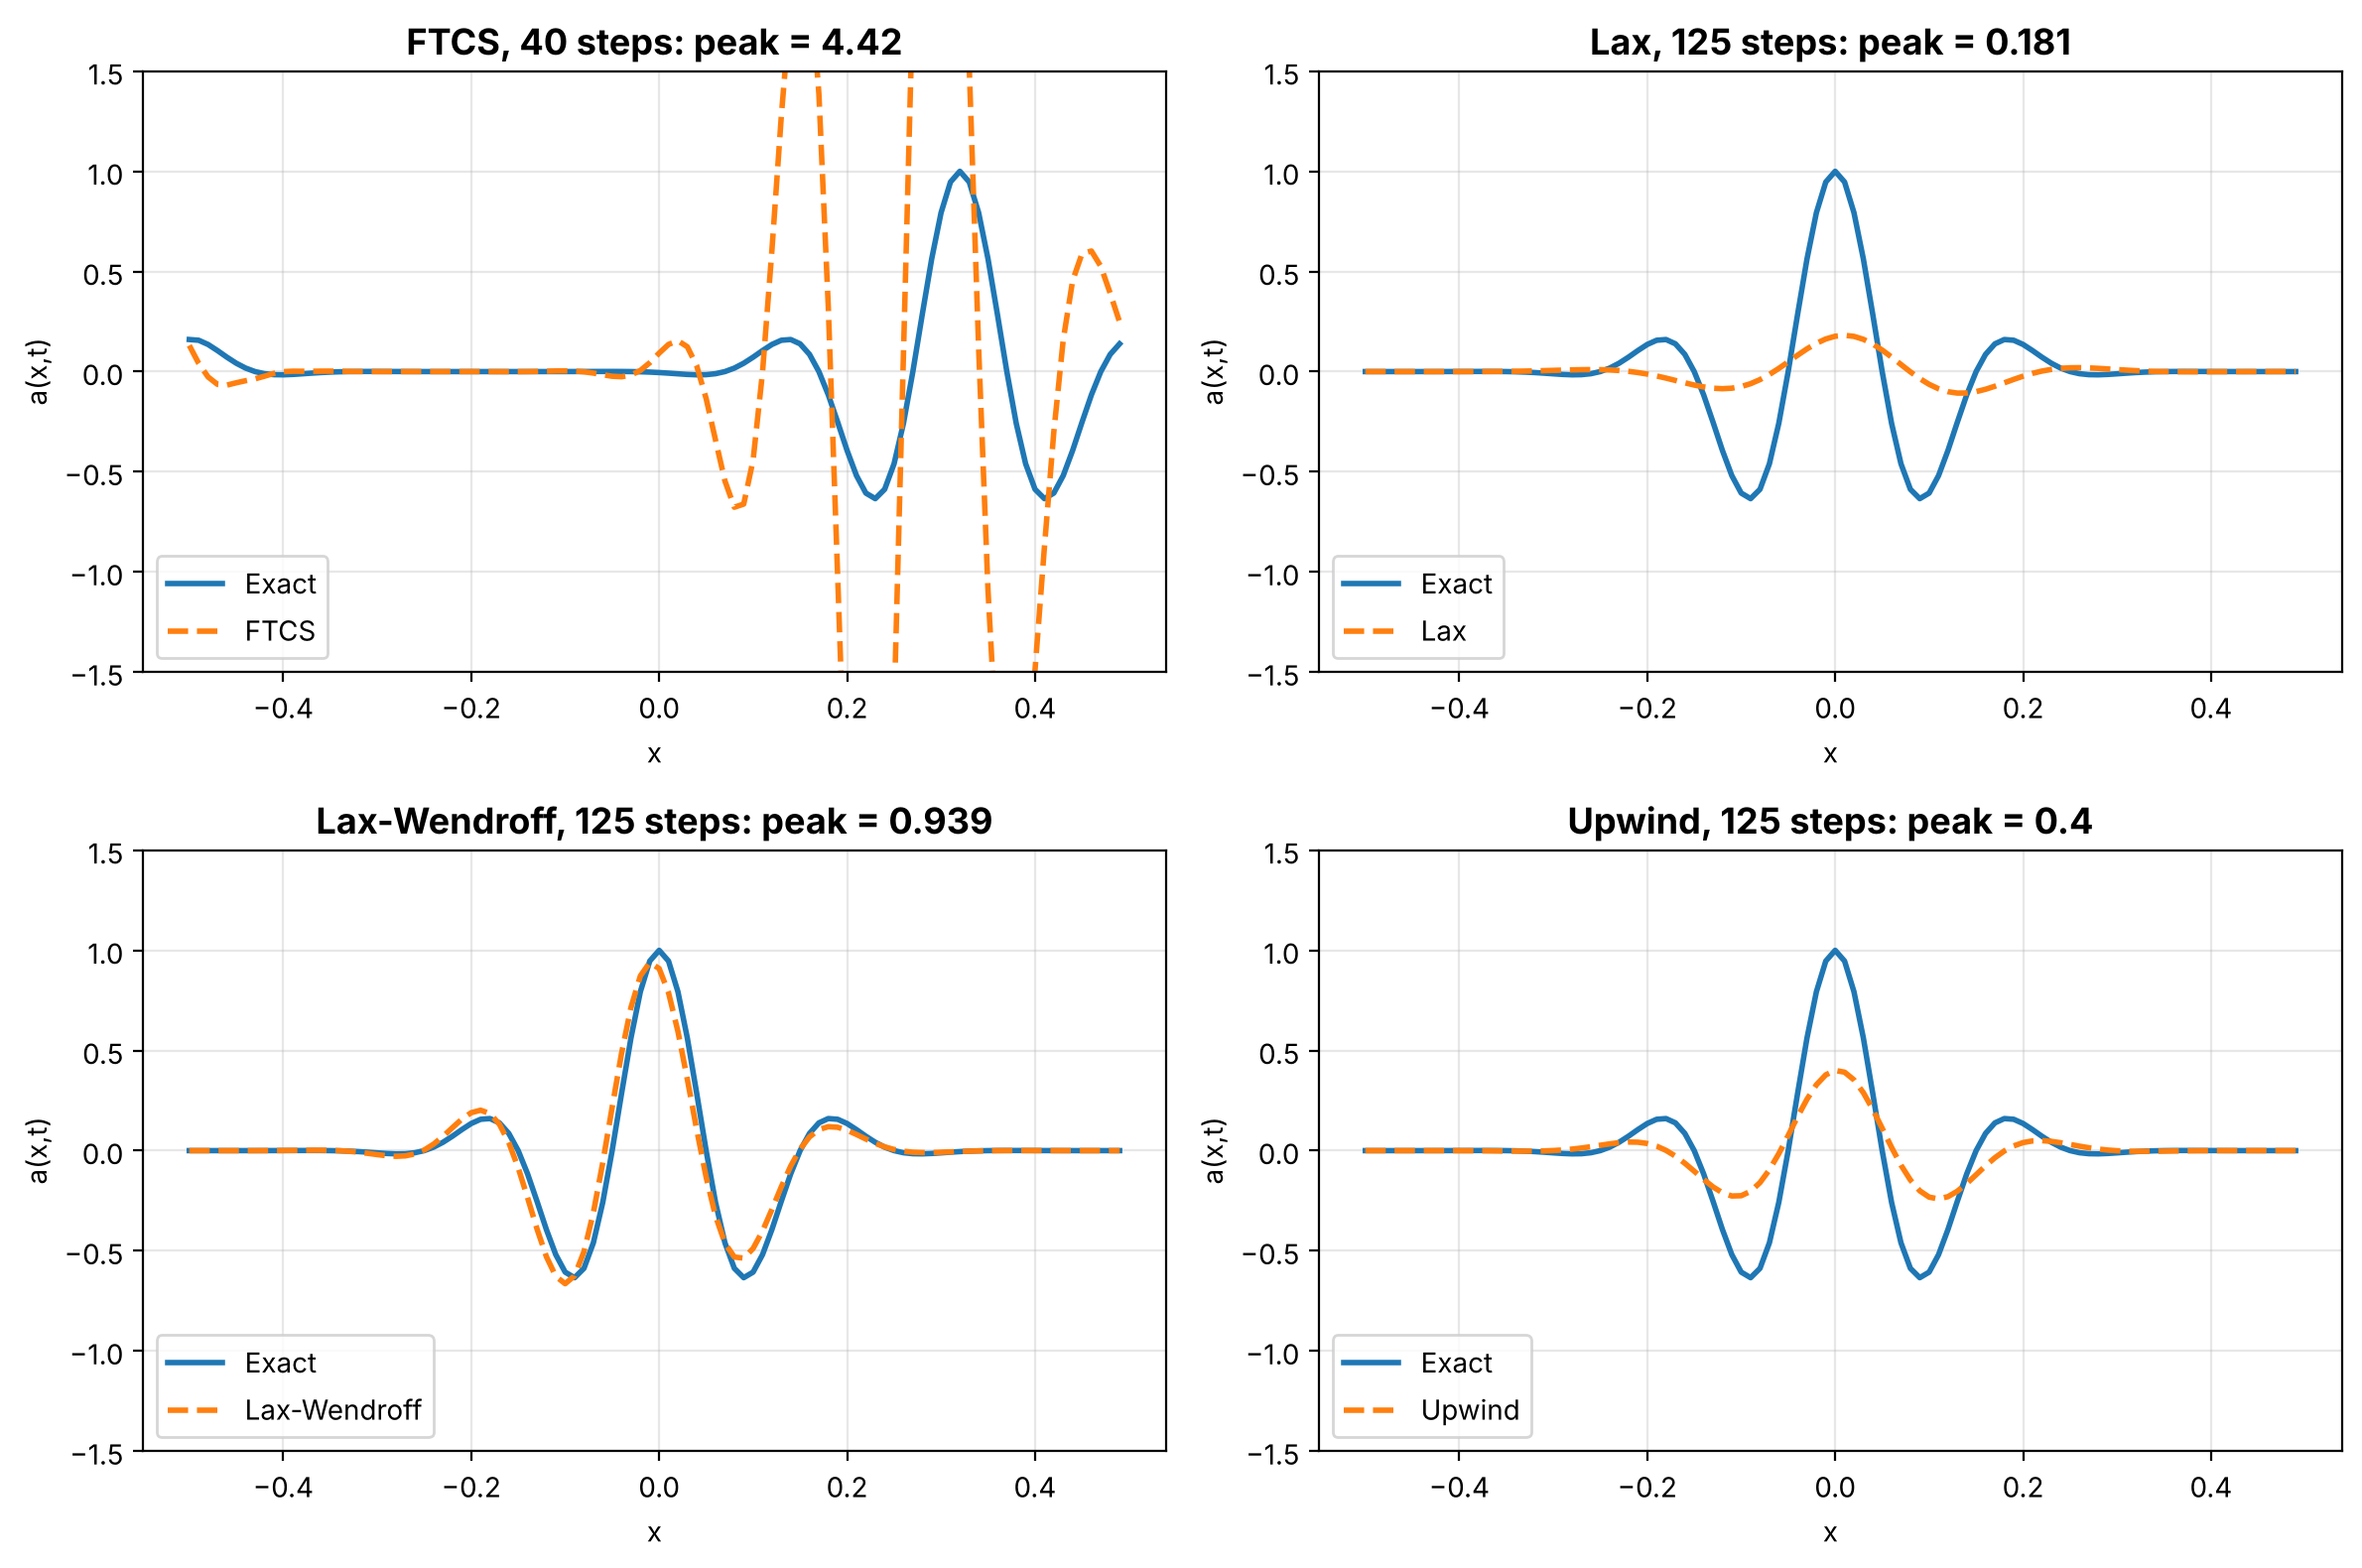

In [2]:
def advect(method, N=100, L=1., c=1., tau=0.008, nstep=None):
    """Run advect with the given method; return x, initial a, final a."""
    h = L/N
    x = np.arange(N)*h - L/2.
    coeff = -c*tau/(2.*h)
    coefflw = 2*coeff**2
    sigma = 0.1
    a = np.cos(np.pi/sigma*x) * np.exp(-x**2/(2*sigma**2))
    a0 = a.copy()
    ip = np.arange(N) + 1;  ip[N-1] = 0
    im = np.arange(N) - 1;  im[0] = N-1
    if nstep is None:
        nstep = int(round(L/(c*tau)))     # one full circuit
    for istep in range(nstep):
        if method == 1:
            a[:] = a[:] + coeff*(a[ip] - a[im])
        elif method == 2:
            a[:] = 0.5*(a[ip] + a[im]) + coeff*(a[ip] - a[im])
        elif method == 3:
            a[:] = a[:] + coeff*(a[ip] - a[im]) + coefflw*(a[ip] + a[im] - 2*a[:])
        else:
            a[:] = a[:] + 2*coeff*(a[:] - a[im])
    return x, a0, a

def exact(x, t, L=1., c=1., sigma=0.1):
    """Exact solution: the initial pulse shifted by ct (wrapped periodically)."""
    xs = (x - c*t + L/2.) % L - L/2.
    return np.cos(np.pi/sigma*xs) * np.exp(-xs**2/(2*sigma**2))

tau = 0.008
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, m in zip(axes.flatten(), [1, 2, 3, 4]):
    nstep = 40 if m == 1 else 125      # FTCS blows up, so stop it early
    x, a0, af = advect(m, tau=tau, nstep=nstep)
    ax.plot(x, exact(x, nstep*tau), '-', label='Exact', linewidth=2)
    ax.plot(x, af, '--', label=names[m], linewidth=2)
    ax.set_ylim(-1.5, 1.5)
    ax.set_title(f'{names[m]}, {nstep} steps: peak = {np.max(np.abs(af)):.3g}', fontsize=13, fontweight='bold')
    ax.set_xlabel('x'); ax.set_ylabel('a(x,t)')
    ax.legend(loc='lower left'); ax.grid(True, alpha=0.3)
    print(f"{names[m]:13s} peak after {nstep} steps: {np.max(np.abs(af)):.3g}")
plt.tight_layout()
plt.show()

## Choosing τ: the CFL number

Lax method, N = 100, one full circuit at each value of cτ/h.

c*tau/h = 0.5: peak after one circuit = 0.0326
c*tau/h = 0.8: peak after one circuit = 0.181
c*tau/h = 1.0: peak after one circuit = 1
c*tau/h = 1.1: peak after one circuit = 3.07


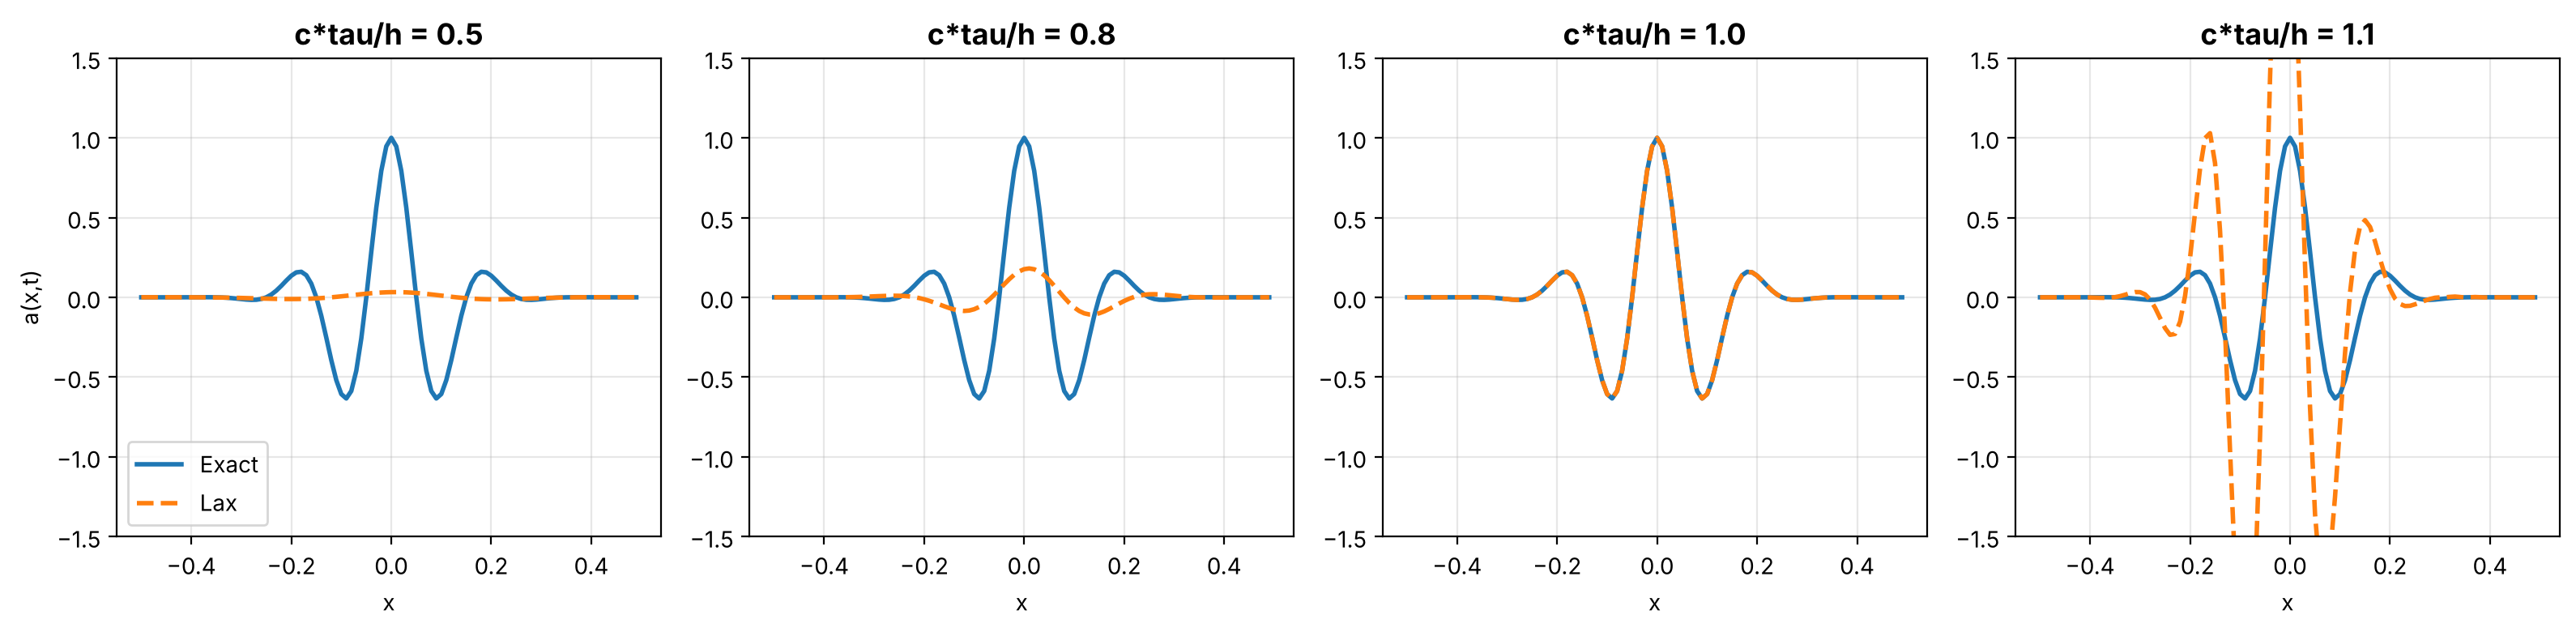

In [3]:
h = L/N
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, cfl in zip(axes, [0.5, 0.8, 1.0, 1.1]):
    tau = cfl*h/c
    x, a0, af = advect(2, tau=tau)
    ax.plot(x, a0, '-', linewidth=2, label='Exact')
    ax.plot(x, af, '--', linewidth=2, label='Lax')
    ax.set_ylim(-1.5, 1.5)
    ax.set_title(f'c*tau/h = {cfl}', fontsize=13, fontweight='bold')
    ax.set_xlabel('x'); ax.grid(True, alpha=0.3)
    print(f"c*tau/h = {cfl}: peak after one circuit = {np.max(np.abs(af)):.3g}")
axes[0].set_ylabel('a(x,t)'); axes[0].legend(loc='lower left')
plt.tight_layout()
plt.show()